# Household Electricity Forecasting: Modeling

Input: `data/model_df.csv` and `data/hourly.csv`, produced by the data-preparation notebook.

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "lines.linewidth": 1.2,
    "font.size": 10,
})
BLUE = "#2a78d6"
ORANGE = "#eb6834"

## Load prepared data and chronological split

In [3]:
model_df = pd.read_csv("data/model_df.csv", index_col="datetime", parse_dates=True)
hourly = pd.read_csv("data/hourly.csv", index_col="datetime", parse_dates=True)

FEATURES = [c for c in model_df.columns if c not in ("target", "split")]

train = model_df[model_df["split"] == "train"]
val = model_df[model_df["split"] == "val"]
test = model_df[model_df["split"] == "test"]

X_train, y_train = train[FEATURES], train["target"]
X_val, y_val = val[FEATURES], val["target"]
X_test, y_test = test[FEATURES], test["target"]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(part):>6} 行   {part.index.min()}  到  {part.index.max()}")

Train        23370 行   2006-12-23 18:00:00  到  2009-09-06 23:00:00
Validation    5008 行   2009-09-07 00:00:00  到  2010-04-12 19:00:00
Test          5009 行   2010-04-12 20:00:00  到  2010-11-26 20:00:00


## Evaluation function

In [4]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "R2": r2_score(y_true, y_pred),
    }

results = {}
test_predictions = {}

## Model 1: Naive persistence baseline

Forecast for the next hour = consumption observed in the current (most recent) hour, i.e. `lag_1`.

In [5]:
start = time.perf_counter()
naive_val_pred = val["lag_1"]
naive_test_pred = test["lag_1"]
naive_time = time.perf_counter() - start

naive_val = evaluate(y_val, naive_val_pred)
naive_test = evaluate(y_test, naive_test_pred)

results["Naive persistence"] = {
    "Val MAE": naive_val["MAE"],
    "Test MAE": naive_test["MAE"],
    "Test RMSE": naive_test["RMSE"],
    "Test MAPE (%)": naive_test["MAPE (%)"],
    "Test R2": naive_test["R2"],
    "Train time (s)": naive_time,
}
test_predictions["Naive persistence"] = naive_test_pred

pd.DataFrame(results).T.round(3)

,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Train time (s)
Naive persistence,0.466,0.386,0.584,46.401,0.315,0.0


In [6]:
def record(name, val_pred, test_pred, train_time):
    val_scores = evaluate(y_val, val_pred)
    test_scores = evaluate(y_test, test_pred)
    results[name] = {
        "Val MAE": val_scores["MAE"],
        "Test MAE": test_scores["MAE"],
        "Test RMSE": test_scores["RMSE"],
        "Test MAPE (%)": test_scores["MAPE (%)"],
        "Test R2": test_scores["R2"],
        "Train time (s)": train_time,
    }
    test_predictions[name] = pd.Series(test_pred, index=y_test.index)
    return pd.DataFrame(results).T.round(3)

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_model = make_pipeline(StandardScaler(), LinearRegression())

start = time.perf_counter()
lr_model.fit(X_train, y_train)
lr_time = time.perf_counter() - start

lr_val_pred = lr_model.predict(X_val)
lr_test_pred = lr_model.predict(X_test)

record("Linear regression", lr_val_pred, lr_test_pred, lr_time)

,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Train time (s)
Naive persistence,0.466,0.386,0.584,46.401,0.315,0.000
Linear regression,0.420,0.362,0.502,49.958,0.495,0.018


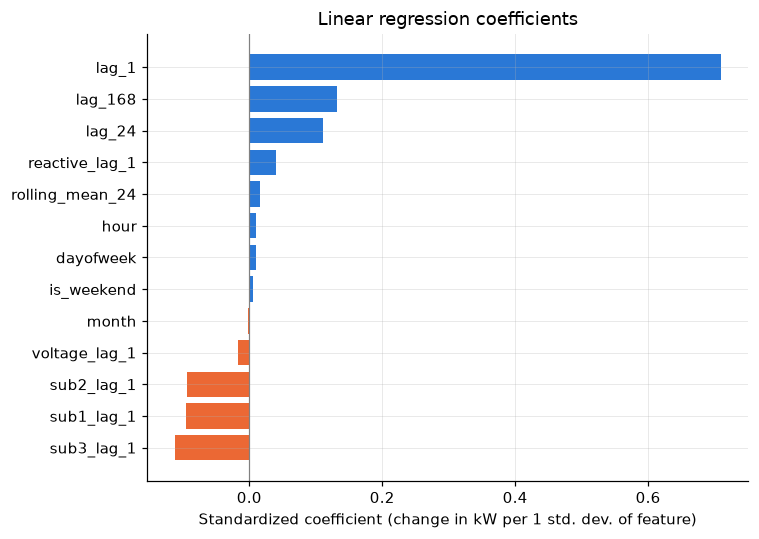

lag_1              0.709
lag_168            0.132
sub3_lag_1        -0.112
lag_24             0.111
sub1_lag_1        -0.095
sub2_lag_1        -0.093
reactive_lag_1     0.040
voltage_lag_1     -0.018
rolling_mean_24    0.017
hour               0.010
dayofweek          0.010
is_weekend         0.006
month             -0.001
dtype: float64

In [8]:
lr_coefs = pd.Series(lr_model[-1].coef_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(lr_coefs.index, lr_coefs, color=[BLUE if v > 0 else ORANGE for v in lr_coefs])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Standardized coefficient (change in kW per 1 std. dev. of feature)")
ax.set_title("Linear regression coefficients")
plt.tight_layout()
plt.show()

lr_coefs.sort_values(key=abs, ascending=False).round(3)

In [9]:
vif = {}
for feature in FEATURES:
    others = [f for f in FEATURES if f != feature]
    r2 = LinearRegression().fit(X_train[others], X_train[feature]).score(X_train[others], X_train[feature])
    vif[feature] = 1 / (1 - r2)

pd.Series(vif, name="VIF").sort_values(ascending=False).round(2)

lag_1              5.11
is_weekend         2.74
dayofweek          2.67
sub3_lag_1         2.29
rolling_mean_24    1.71
sub1_lag_1         1.59
sub2_lag_1         1.52
lag_24             1.52
hour               1.39
lag_168            1.36
voltage_lag_1      1.33
reactive_lag_1     1.29
month              1.02
Name: VIF, dtype: float64

In [10]:
from xgboost import XGBRegressor
from sklearn.model_selection import ParameterSampler

param_space = {
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}
candidates = list(ParameterSampler(param_space, n_iter=30, random_state=42))

search_log = []
start = time.perf_counter()
for i, params in enumerate(candidates):
    model = XGBRegressor(
        n_estimators=2000,
        early_stopping_rounds=50,
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
        **params,
    )
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    val_mae = mean_absolute_error(y_val, model.predict(X_val))
    search_log.append({"trial": i, **params, "n_trees": model.best_iteration + 1, "val_mae": val_mae})
search_time = time.perf_counter() - start

search_log = pd.DataFrame(search_log).sort_values("val_mae")
print(f"调参总耗时: {search_time:.1f} 秒")
search_log.head(10).round(4)

调参总耗时: 32.2 秒


,trial,subsample,min_child_weight,max_depth,learning_rate,colsample_bytree,n_trees,val_mae
8,8,0.8,5,8,0.01,0.8,607,0.3520
1,1,1.0,1,8,0.01,0.8,544,0.3530
10,10,0.8,20,6,0.10,1.0,65,0.3531
0,0,0.8,5,6,0.03,0.8,244,0.3534
24,24,0.8,20,8,0.10,0.8,69,0.3541
15,15,0.8,5,5,0.03,0.8,378,0.3543
9,9,0.6,10,5,0.05,0.8,249,0.3545
17,17,0.6,5,5,0.05,1.0,197,0.3547
20,20,1.0,1,5,0.10,0.8,90,0.3553
23,23,1.0,1,5,0.10,1.0,96,0.3556


In [11]:
best_trial = search_log.iloc[0]
best_params = candidates[int(best_trial["trial"])]
best_n_trees = int(best_trial["n_trees"])
print("最优参数:", best_params, " 树的数量:", best_n_trees)

xgb_model = XGBRegressor(
    n_estimators=best_n_trees,
    eval_metric="mae",
    random_state=42,
    n_jobs=-1,
    **best_params,
)

start = time.perf_counter()
xgb_model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
xgb_time = time.perf_counter() - start

xgb_val_pred = xgb_model.predict(X_val)
xgb_test_pred = xgb_model.predict(X_test)

record("XGBoost", xgb_val_pred, xgb_test_pred, xgb_time)

最优参数: {'subsample': 0.8, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 0.8}  树的数量: 607


,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Train time (s)
Naive persistence,0.466,0.386,0.584,46.401,0.315,0.000
Linear regression,0.420,0.362,0.502,49.958,0.495,0.018
XGBoost,0.352,0.311,0.449,41.266,0.595,2.904


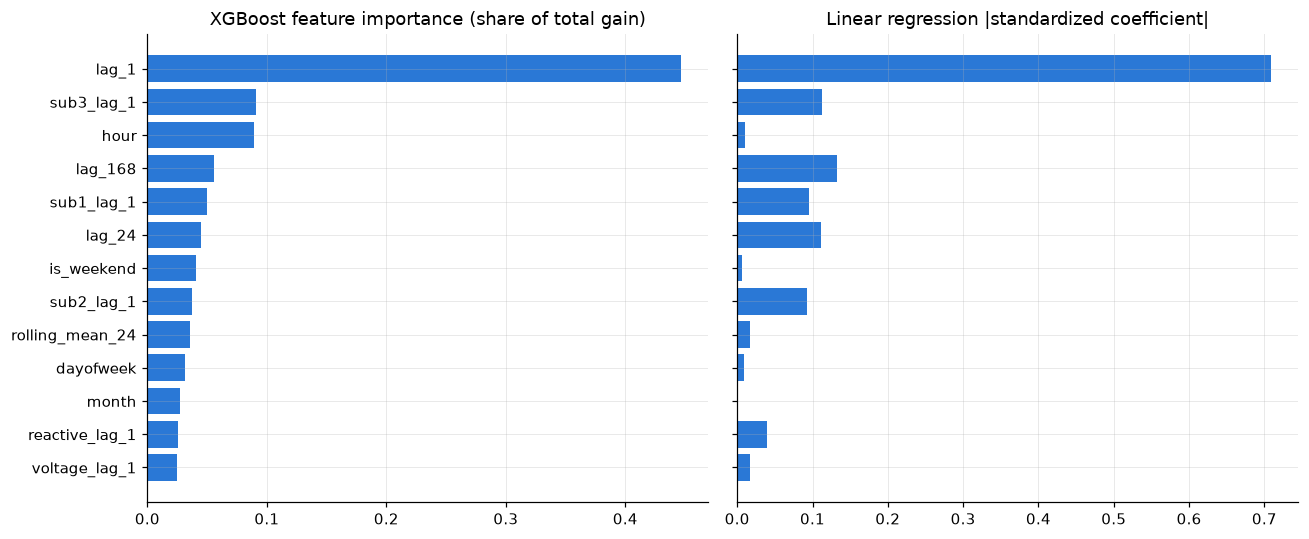

,XGBoost gain share,LR |coef|
lag_1,0.447,0.709
sub3_lag_1,0.091,0.112
hour,0.089,0.010
lag_168,0.056,0.132
sub1_lag_1,0.050,0.095
lag_24,0.045,0.111
is_weekend,0.040,0.006
sub2_lag_1,0.038,0.093
rolling_mean_24,0.035,0.017
dayofweek,0.031,0.010


In [12]:
xgb_gain = pd.Series(xgb_model.get_booster().get_score(importance_type="gain"))
xgb_gain = xgb_gain.reindex(FEATURES).fillna(0)
xgb_gain = xgb_gain / xgb_gain.sum()
order = xgb_gain.sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(order, xgb_gain[order], color=BLUE)
axes[0].set_title("XGBoost feature importance (share of total gain)")
axes[1].barh(order, lr_coefs.abs()[order], color=BLUE)
axes[1].set_title("Linear regression |standardized coefficient|")
plt.tight_layout()
plt.show()

pd.DataFrame({"XGBoost gain share": xgb_gain, "LR |coef|": lr_coefs.abs()}).sort_values("XGBoost gain share", ascending=False).round(3)

In [13]:
lstm_pred = pd.read_csv("data/lstm_predictions.csv", index_col="datetime", parse_dates=True)
lstm_history = pd.read_csv("data/lstm_history.csv")
lstm_time = lstm_history["train_time_s"].iloc[0]

lstm_val_pred = lstm_pred.loc[lstm_pred["split"] == "val", "prediction"].reindex(y_val.index).to_numpy()
lstm_test_pred = lstm_pred.loc[lstm_pred["split"] == "test", "prediction"].reindex(y_test.index).to_numpy()

record("LSTM", lstm_val_pred, lstm_test_pred, lstm_time)

,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Train time (s)
Naive persistence,0.466,0.386,0.584,46.401,0.315,0.000
Linear regression,0.420,0.362,0.502,49.958,0.495,0.018
XGBoost,0.352,0.311,0.449,41.266,0.595,2.904
LSTM,0.368,0.325,0.468,42.286,0.561,208.640


In [14]:
comparison = pd.DataFrame(results).T
naive_mae = comparison.loc["Naive persistence", "Test MAE"]
comparison["Improvement vs naive"] = (1 - comparison["Test MAE"] / naive_mae).map("{:.1%}".format)
comparison.round(3)

,Val MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Train time (s),Improvement vs naive
Naive persistence,0.466,0.386,0.584,46.401,0.315,0.000,0.0%
Linear regression,0.420,0.362,0.502,49.958,0.495,0.018,6.4%
XGBoost,0.352,0.311,0.449,41.266,0.595,2.904,19.5%
LSTM,0.368,0.325,0.468,42.286,0.561,208.640,15.8%


In [16]:
from sklearn.model_selection import ParameterGrid

param_space_ext = {
    "max_depth": [6, 8, 10, 12],
    "learning_rate": [0.005, 0.01, 0.03],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}
candidates_ext = list(ParameterGrid(param_space_ext))

search_log_ext = []
start = time.perf_counter()
for i, params in enumerate(candidates_ext):
    model = XGBRegressor(
        n_estimators=3000,
        early_stopping_rounds=50,
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
        **params,
    )
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    val_mae = mean_absolute_error(y_val, model.predict(X_val))
    search_log_ext.append({"trial": i, **params, "n_trees": model.best_iteration + 1, "val_mae": val_mae})
search_time_ext = time.perf_counter() - start

search_log_ext = pd.DataFrame(search_log_ext).sort_values("val_mae")
print(f"扩大范围搜索耗时: {search_time_ext:.1f} 秒，共 {len(candidates_ext)} 组")
print(f"原来搜索的最优验证集 MAE:   {search_log['val_mae'].min():.4f}")
print(f"扩大范围后的最优验证集 MAE: {search_log_ext['val_mae'].min():.4f}")
search_log_ext.head(10).round(4)

扩大范围搜索耗时: 150.1 秒，共 36 组
原来搜索的最优验证集 MAE:   0.3520
扩大范围后的最优验证集 MAE: 0.3514


,trial,colsample_bytree,learning_rate,max_depth,min_child_weight,subsample,n_trees,val_mae
5,5,0.8,0.005,8,10,0.8,1135,0.3514
4,4,0.8,0.005,8,5,0.8,1122,0.3517
1,1,0.8,0.005,6,5,0.8,1685,0.3519
16,16,0.8,0.010,8,5,0.8,607,0.3520
2,2,0.8,0.005,6,10,0.8,1517,0.3520
17,17,0.8,0.010,8,10,0.8,594,0.3520
26,26,0.8,0.030,6,10,0.8,274,0.3521
14,14,0.8,0.010,6,10,0.8,867,0.3522
13,13,0.8,0.010,6,5,0.8,867,0.3523
0,0,0.8,0.005,6,1,0.8,1517,0.3523


In [17]:
MODEL_COLORS = {
    "Naive persistence": "#8c8c8c",
    "Linear regression": ORANGE,
    "XGBoost": BLUE,
    "LSTM": "#1baf7a",
}
MODELS = list(MODEL_COLORS)

errors = pd.DataFrame({name: test_predictions[name] - y_test for name in MODELS})
abs_errors = errors.abs()

abs_errors.mean().round(3)

Naive persistence    0.386
Linear regression    0.362
XGBoost              0.311
LSTM                 0.325
dtype: float64

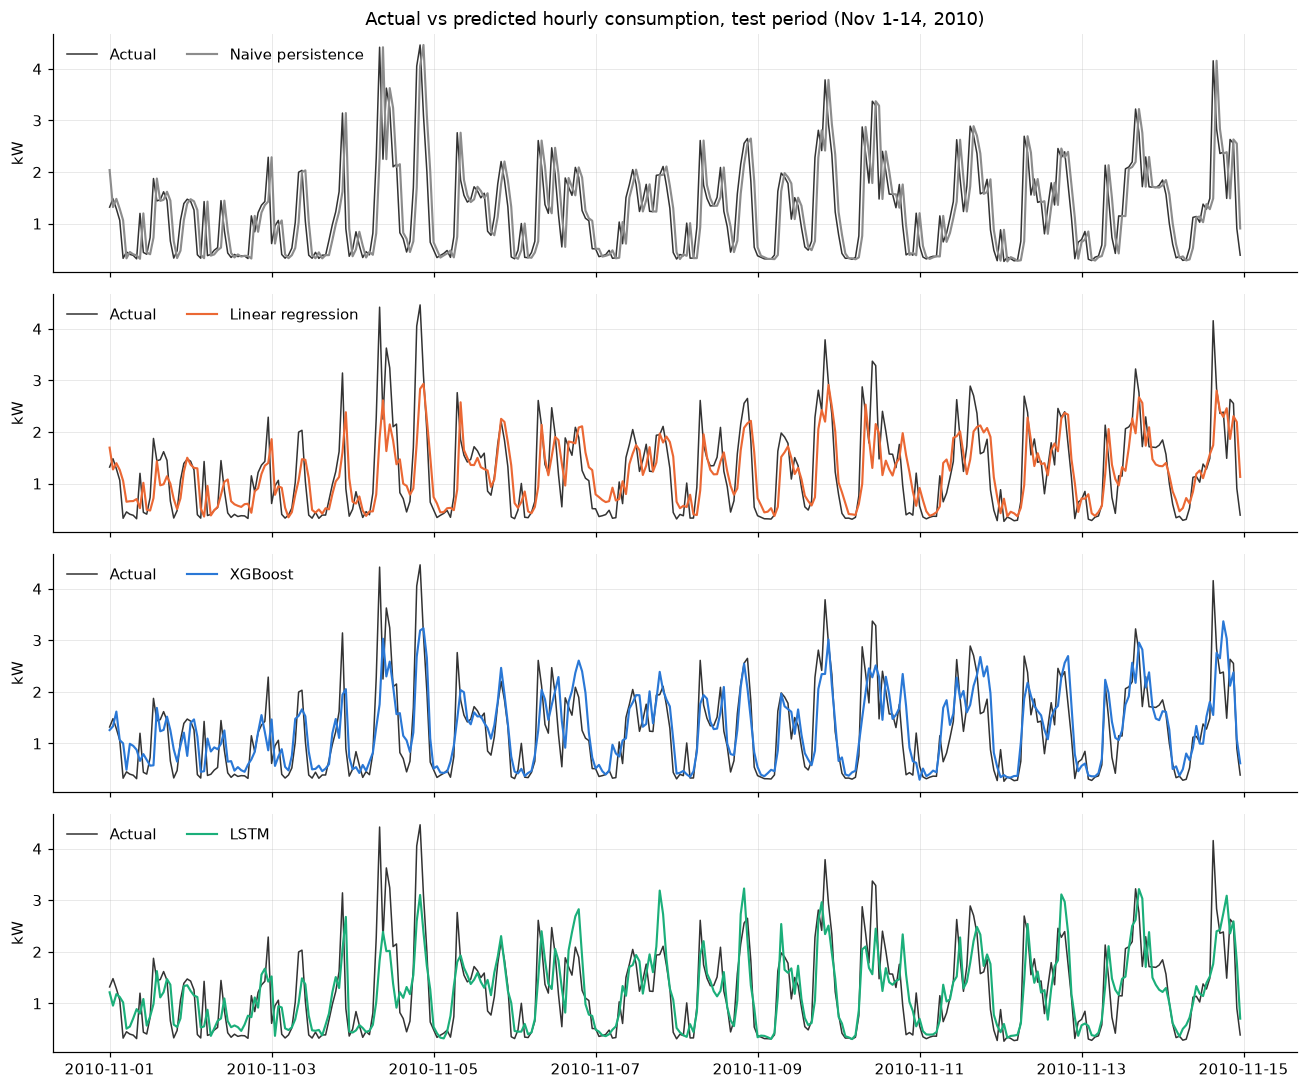

In [18]:
window = slice("2010-11-01", "2010-11-14")
actual = y_test.loc[window]

fig, axes = plt.subplots(len(MODELS), 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, name in zip(axes, MODELS):
    ax.plot(actual.index, actual, color="#333333", linewidth=1, label="Actual")
    ax.plot(actual.index, test_predictions[name].loc[window], color=MODEL_COLORS[name], linewidth=1.4, label=name)
    ax.set_ylabel("kW")
    ax.legend(loc="upper left", frameon=False, ncol=2)
axes[0].set_title("Actual vs predicted hourly consumption, test period (Nov 1-14, 2010)")
plt.tight_layout()
plt.show()

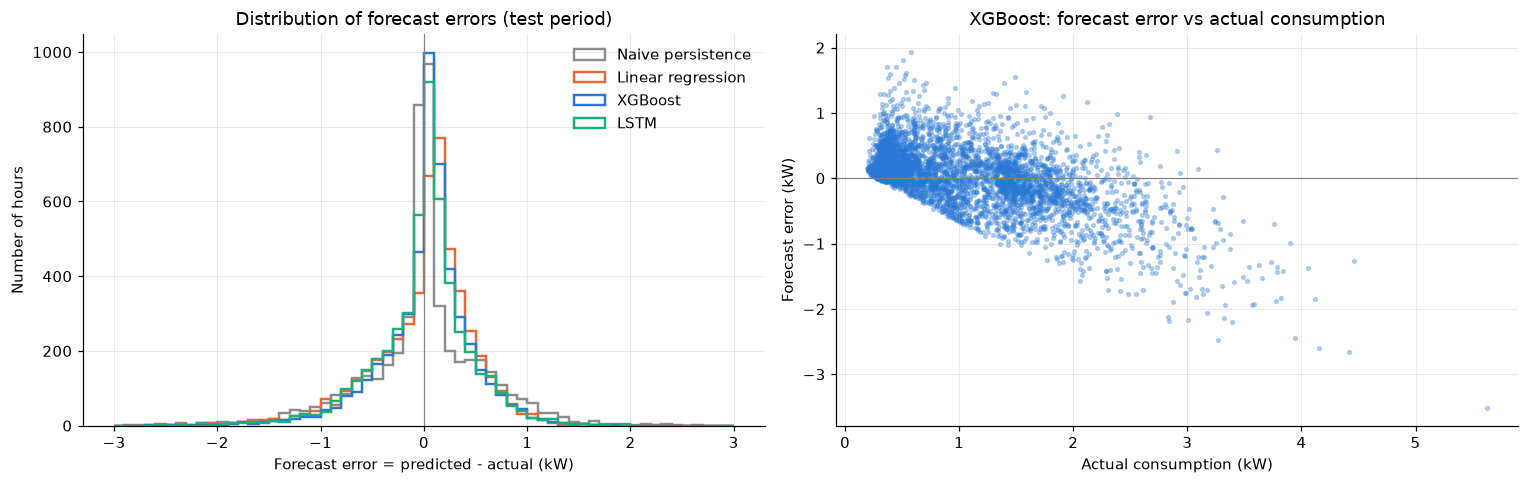

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

bins = np.linspace(-3, 3, 61)
for name in MODELS:
    axes[0].hist(errors[name], bins=bins, histtype="step", linewidth=1.6, color=MODEL_COLORS[name], label=name)
axes[0].axvline(0, color="grey", linewidth=0.8)
axes[0].set_xlabel("Forecast error = predicted - actual (kW)")
axes[0].set_ylabel("Number of hours")
axes[0].set_title("Distribution of forecast errors (test period)")
axes[0].legend(frameon=False)

axes[1].scatter(y_test, errors["XGBoost"], s=6, alpha=0.3, color=BLUE)
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Actual consumption (kW)")
axes[1].set_ylabel("Forecast error (kW)")
axes[1].set_title("XGBoost: forecast error vs actual consumption")

plt.tight_layout()
plt.show()

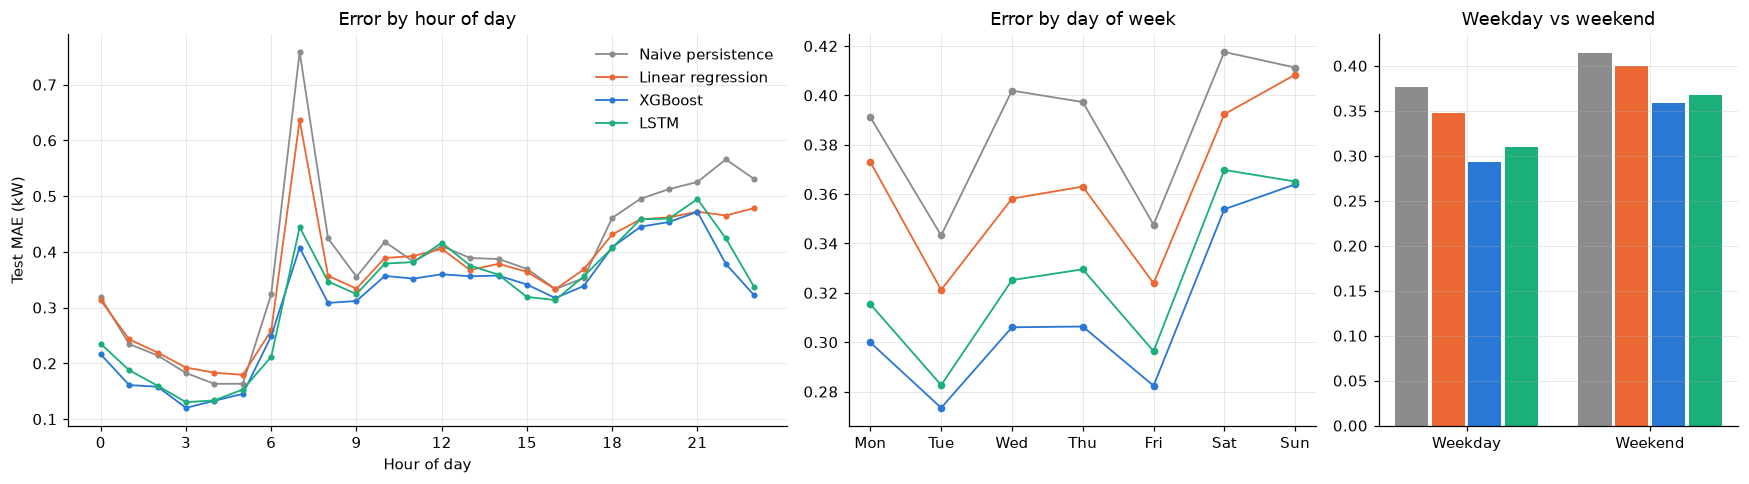

XGBoost 误差最大的 3 个小时:
datetime
21    0.472
20    0.454
19    0.445
Name: XGBoost, dtype: float64


,Naive persistence,Linear regression,XGBoost,LSTM
Weekday,0.376,0.348,0.293,0.310
Weekend,0.414,0.400,0.359,0.367


In [20]:
by_hour = abs_errors.groupby(y_test.index.hour).mean()
by_dow = abs_errors.groupby(y_test.index.day_of_week).mean()
by_daytype = abs_errors.groupby(np.where(y_test.index.day_of_week >= 5, "Weekend", "Weekday")).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1.3, 1]})

for name in MODELS:
    axes[0].plot(by_hour.index, by_hour[name], color=MODEL_COLORS[name], marker="o", markersize=3, label=name)
    axes[1].plot(by_dow.index, by_dow[name], color=MODEL_COLORS[name], marker="o", markersize=4)
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Test MAE (kW)")
axes[0].set_title("Error by hour of day")
axes[0].legend(frameon=False)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("Error by day of week")

width = 0.2
for i, name in enumerate(MODELS):
    axes[2].bar(np.arange(2) + (i - 1.5) * width, by_daytype[name], width=width * 0.9, color=MODEL_COLORS[name])
axes[2].set_xticks(range(2))
axes[2].set_xticklabels(by_daytype.index)
axes[2].set_title("Weekday vs weekend")

plt.tight_layout()
plt.show()

print("XGBoost 误差最大的 3 个小时:")
print(by_hour["XGBoost"].sort_values(ascending=False).head(3).round(3))
by_daytype.round(3)

In [21]:
spike_threshold = y_train.quantile(0.95)
is_high = y_test > spike_threshold
is_jump = (y_test - test["lag_1"]) > 1.0

spike_summary = pd.DataFrame({
    "MAE, normal hours": abs_errors[~is_high & ~is_jump].mean(),
    "MAE, high-consumption hours": abs_errors[is_high].mean(),
    "Mean error, high-consumption": errors[is_high].mean(),
    "MAE, sudden jumps": abs_errors[is_jump].mean(),
    "Mean error, sudden jumps": errors[is_jump].mean(),
})

print(f"高用电阈值（训练集第 95 百分位）: {spike_threshold:.2f} kW，测试集中有 {is_high.sum()} 个小时超过")
print(f"突然跳升（比上一小时高出 1 kW 以上）: 测试集中有 {is_jump.sum()} 个小时")
spike_summary.round(3)

高用电阈值（训练集第 95 百分位）: 2.93 kW，测试集中有 73 个小时超过
突然跳升（比上一小时高出 1 kW 以上）: 测试集中有 265 个小时


,"MAE, normal hours","MAE, high-consumption hours","Mean error, high-consumption","MAE, sudden jumps","Mean error, sudden jumps"
Naive persistence,0.326,1.381,-1.209,1.437,-1.437
Linear regression,0.308,1.569,-1.555,1.254,-1.254
XGBoost,0.273,1.329,-1.311,0.945,-0.941
LSTM,0.283,1.415,-1.395,1.007,-1.005
